
## CAT Assignment 2

**Name:** Balakumaran S <br>

**Reg. No.:** 3122247001010

## 0. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from scipy import stats
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, learning_curve)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110; plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = .3
SEED = 42; np.random.seed(SEED)

BANKNOTE_FILE = "data_banknote_authentication.txt"   # .csv (with header) or the UCI .txt (no header)
TEST_SIZE = 0.2

## Data loading, split and helper code


In [2]:
def make_synthetic_banknote(n=1372, seed=1):
    rng = np.random.default_rng(seed)
    n1 = int(n * 0.445); n0 = n - n1
    g = np.column_stack([rng.normal(2.3, 2.0, n0), rng.normal(4.0, 5.0, n0), rng.normal(0.8, 3.2, n0), rng.normal(-1.2, 2.1, n0)])
    f = np.column_stack([rng.normal(-1.9, 1.9, n1), rng.normal(-0.9, 5.0, n1), rng.normal(2.1, 5.3, n1), rng.normal(-1.2, 2.2, n1)])
    X = np.vstack([g, f]); y = np.r_[np.zeros(n0), np.ones(n1)]
    d = pd.DataFrame(X, columns=["variance", "skewness", "curtosis", "entropy"]); d["class"] = y.astype(int)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

if os.path.exists(BANKNOTE_FILE):
    bn = pd.read_csv(BANKNOTE_FILE)
    try:
        float(bn.columns[0]); bn = pd.read_csv(BANKNOTE_FILE, header=None)
        bn.columns = ["variance", "skewness", "curtosis", "entropy", "class"]
    except ValueError:
        pass
else:
    print(f"WARNING: '{BANKNOTE_FILE}' not found -> using SYNTHETIC stand-in data.")
    bn = make_synthetic_banknote()

bn = bn.drop_duplicates().reset_index(drop=True)
label_col = bn.columns[-1]; feats = list(bn.columns[:-1])
Xc = bn[feats].values.astype(float); yc = bn[label_col].values.astype(int)
print("Shape:", bn.shape, "| features:", feats, "| class counts:", np.bincount(yc), "| missing:", int(bn.isna().sum().sum()))

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=TEST_SIZE, random_state=SEED, stratify=yc)
mu_c, sd_c = Xc_tr.mean(0), Xc_tr.std(0); sd_c[sd_c == 0] = 1
Xc_tr_s, Xc_te_s = (Xc_tr - mu_c) / sd_c, (Xc_te - mu_c) / sd_c
print("Train:", Xc_tr.shape, "| Test:", Xc_te.shape)

# ---------------- helpers: logistic regression from scratch (matrix form, gradient descent) ----------------
def add_bias(X): return np.hstack([np.ones((X.shape[0], 1)), X])
def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def acc(y, yh): return float(np.mean(y == yh))
def std_fit(X):
    m, s = X.mean(0), X.std(0); s[s == 0] = 1.0; return m, s

class LogisticGD:
    # loss = mean BCE + lam/(2n) * ||w||^2   (bias not penalised);  sklearn equivalent: C = 1/lam
    def __init__(self, lam=0.0, lr=0.5, n_iter=3000): self.lam, self.lr, self.n_iter = lam, lr, n_iter
    def fit(self, X, y):
        n, d = X.shape; Xb = add_bias(X); y = y.reshape(-1, 1).astype(float)
        R = np.ones((d + 1, 1)); R[0] = 0; self.theta = np.zeros((d + 1, 1)); self.hist = []
        lr_eff = min(self.lr, 1.0 / (self.lam / n + 1.0))   # keeps GD stable for large lambda
        for _ in range(self.n_iter):
            p = sigmoid(Xb @ self.theta)
            self.hist.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)) + self.lam * np.sum((R * self.theta) ** 2) / (2 * n))
            self.theta -= lr_eff * (Xb.T @ (p - y) + self.lam * R * self.theta) / n
        return self
    def predict_proba(self, X): return sigmoid(add_bias(X) @ self.theta).ravel()
    def predict(self, X): return (self.predict_proba(X) >= .5).astype(int)

summary = {}          # collects headline numbers for the final verdict (Q8)

Shape: (1348, 5) | features: ['variance', 'skewness', 'curtosis', 'entropy'] | class counts: [738 610] | missing: 0
Train: (1078, 4) | Test: (270, 4)


## Q1. Linear model baseline: Logistic Regression with and without $\ell_2$

In [3]:
def cv_lambda_gd(X, y, lams, k=5):
    skf = StratifiedKFold(k, shuffle=True, random_state=SEED); out = []
    for lam in lams:
        a = []
        for tr, va in skf.split(X, y):
            m_, s_ = std_fit(X[tr])
            mdl = LogisticGD(lam, n_iter=1500).fit((X[tr] - m_) / s_, y[tr])
            a.append(acc(y[va], mdl.predict((X[va] - m_) / s_)))
        out.append(np.mean(a))
    return np.array(out)

lam_grid = np.logspace(-3, 3, 13)
cv_acc = cv_lambda_gd(Xc_tr, yc_tr, lam_grid)
best_lam = float(lam_grid[np.flatnonzero(cv_acc >= cv_acc.max() - 1e-12)[-1]])
print(f"CV-selected lambda = {best_lam:.4g} (CV accuracy {cv_acc.max():.4f})")

t0 = time.time(); lr_plain = LogisticGD(0.0).fit(Xc_tr_s, yc_tr); t_plain = time.time() - t0
t0 = time.time(); lr_l2 = LogisticGD(best_lam).fit(Xc_tr_s, yc_tr); t_l2 = time.time() - t0

rows = []
for name, m in [("No regularisation (λ=0)", lr_plain), (f"ℓ2, CV-selected (λ={best_lam:.3g})", lr_l2),
                ("ℓ2, λ=1", LogisticGD(1.0).fit(Xc_tr_s, yc_tr)), ("ℓ2, λ=10", LogisticGD(10.0).fit(Xc_tr_s, yc_tr)),
                ("ℓ2, λ=100", LogisticGD(100.0).fit(Xc_tr_s, yc_tr))]:
    tr_a, te_a = acc(yc_tr, m.predict(Xc_tr_s)), acc(yc_te, m.predict(Xc_te_s))
    rows.append([name, tr_a, te_a, tr_a - te_a, np.linalg.norm(m.theta[1:])])
q1 = pd.DataFrame(rows, columns=["Model", "Train acc", "Test acc", "Gap (train−test)", "‖w‖"])
display(q1.round(4))

sk = LogisticRegression(C=1.0, max_iter=5000).fit(Xc_tr_s, yc_tr)       # sanity check, lambda=1 <-> C=1
print("Sanity check vs scikit-learn (λ=1):  ours =", round(acc(yc_te, LogisticGD(1.0).fit(Xc_tr_s, yc_tr).predict(Xc_te_s)), 4), "| sklearn =", round(acc(yc_te, sk.predict(Xc_te_s)), 4))

CV-selected lambda = 0.3162 (CV accuracy 0.9944)


,Model,Train acc,Test acc,Gap (train−test),‖w‖
0,No regularisation (λ=0),0.9944,0.9852,0.0092,11.8581
1,"ℓ2, CV-selected (λ=0.316)",0.9944,0.9852,0.0092,9.9931
2,"ℓ2, λ=1",0.9944,0.9852,0.0092,7.9434
3,"ℓ2, λ=10",0.9889,0.9852,0.0037,4.1179
4,"ℓ2, λ=100",0.9518,0.9556,-0.0038,1.5268


Sanity check vs scikit-learn (λ=1):  ours = 0.9852 | sklearn = 0.9852


## Q2. Accuracy as a function of $\lambda$ – overfitting and generalisation

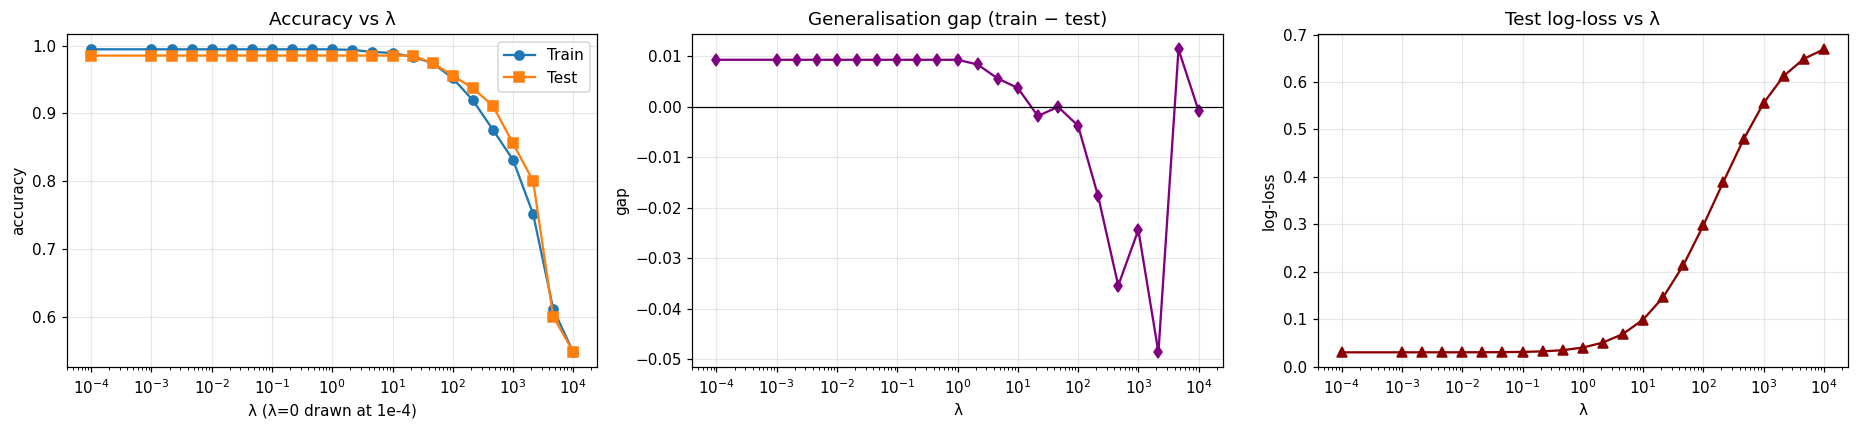

Best test accuracy 0.9852 at λ=0 | lowest test log-loss 0.0300 at λ=0
Largest train−test gap = +0.0113 (at λ=4642); at λ=0: +0.0092
Accuracy at the largest λ=10000: train=0.5473, test=0.5481


In [4]:
lams = np.r_[0, np.logspace(-3, 4, 22)]
tr_a, te_a, cv_a, te_ll = [], [], [], []
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for lam in lams:
    m = LogisticGD(lam, n_iter=2500).fit(Xc_tr_s, yc_tr)
    tr_a.append(acc(yc_tr, m.predict(Xc_tr_s))); te_a.append(acc(yc_te, m.predict(Xc_te_s)))
    p = np.clip(m.predict_proba(Xc_te_s), 1e-12, 1 - 1e-12); te_ll.append(-np.mean(yc_te * np.log(p) + (1 - yc_te) * np.log(1 - p)))
tr_a, te_a, te_ll = map(np.array, (tr_a, te_a, te_ll))
xs = np.where(lams == 0, 1e-4, lams)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].semilogx(xs, tr_a, "o-", label="Train"); ax[0].semilogx(xs, te_a, "s-", label="Test")
ax[0].set_title("Accuracy vs λ"); ax[0].set_xlabel("λ (λ=0 drawn at 1e-4)"); ax[0].set_ylabel("accuracy"); ax[0].legend()
ax[1].semilogx(xs, tr_a - te_a, "d-", color="purple"); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Generalisation gap (train − test)"); ax[1].set_xlabel("λ"); ax[1].set_ylabel("gap")
ax[2].semilogx(xs, te_ll, "^-", color="darkred"); ax[2].set_title("Test log-loss vs λ"); ax[2].set_xlabel("λ"); ax[2].set_ylabel("log-loss")
plt.tight_layout(); plt.show()

i_best = int(np.argmax(te_a)); i_ll = int(np.argmin(te_ll))
print(f"Best test accuracy {te_a[i_best]:.4f} at λ={lams[i_best]:.4g} | lowest test log-loss {te_ll[i_ll]:.4f} at λ={lams[i_ll]:.4g}")
print(f"Largest train−test gap = {np.max(tr_a - te_a):+.4f} (at λ={lams[int(np.argmax(tr_a - te_a))]:.4g}); at λ=0: {tr_a[0] - te_a[0]:+.4f}")
print(f"Accuracy at the largest λ={lams[-1]:.0f}: train={tr_a[-1]:.4f}, test={te_a[-1]:.4f}")

## Q3. 3-D decision-boundary visualisation and class separability

,feature,weight,|w|
1,skewness,-7.256,7.256
2,curtosis,-6.693,6.693
0,variance,-6.564,6.564
3,entropy,0.272,0.272


Selected features: ['skewness', 'curtosis', 'variance']
3-feature LR : train=0.9954  test=0.9852  (4 test errors)
3-feature MLP: train=0.9954  test=0.9852
4-feature LR : test=0.9852   -> information lost by dropping 'entropy': +0.0000
Median |distance| of test points to the plane = 0.62; fraction within 0.25 of the plane = 0.052


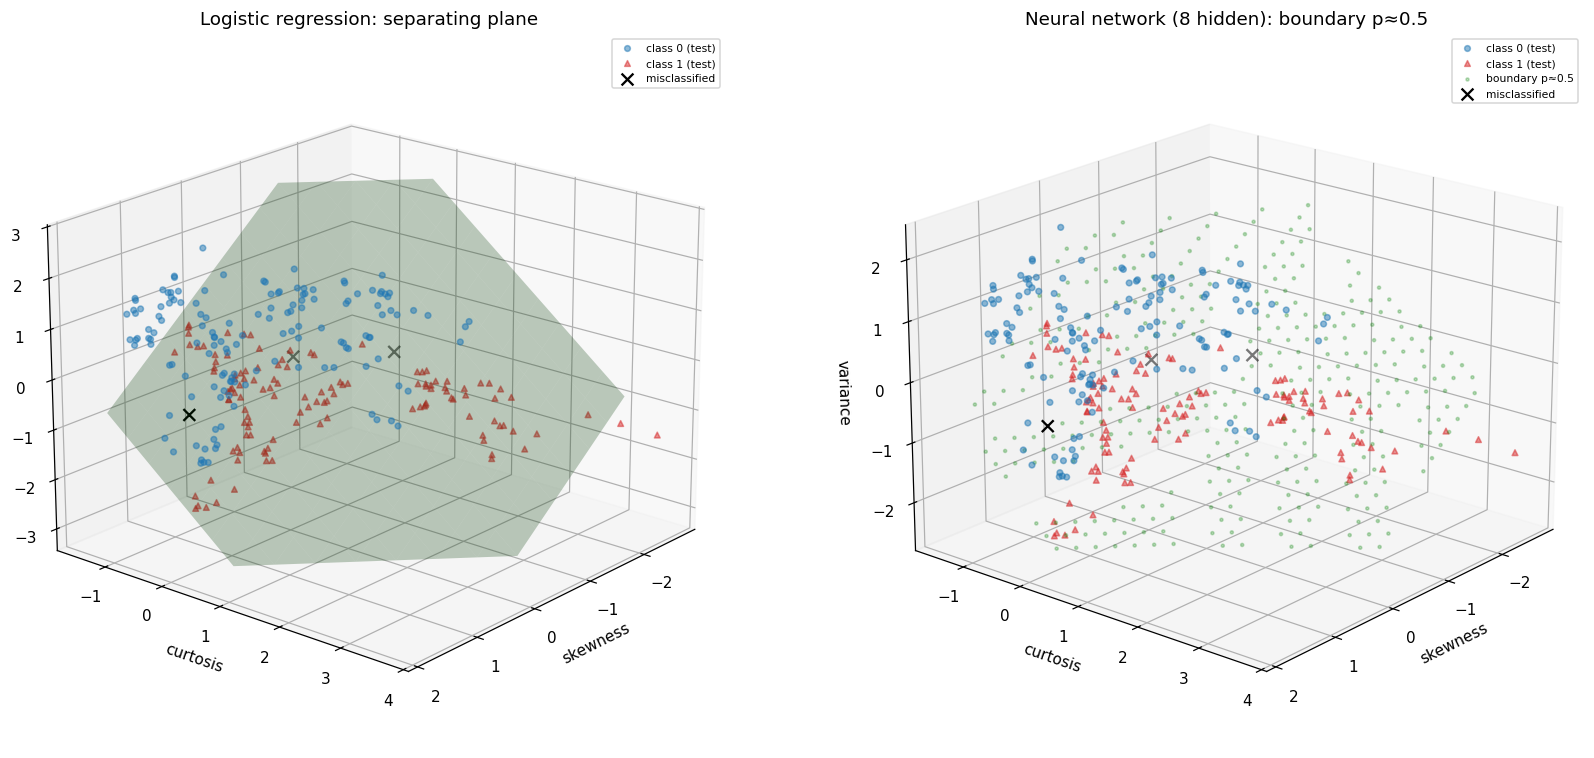

In [5]:
imp = pd.DataFrame({"feature": feats, "weight": lr_plain.theta[1:, 0]}); imp["|w|"] = imp.weight.abs()
imp = imp.sort_values("|w|", ascending=False); display(imp.round(3))
top3 = list(imp.feature.head(3)); idx3 = [feats.index(f) for f in top3]; print("Selected features:", top3)

X3_tr, X3_te = Xc_tr_s[:, idx3], Xc_te_s[:, idx3]
m3 = LogisticGD(0.0).fit(X3_tr, yc_tr)
mlp3 = MLPClassifier((8,), max_iter=2000, random_state=SEED).fit(X3_tr, yc_tr)
pred3 = m3.predict(X3_te); wrong = pred3 != yc_te
print(f"3-feature LR : train={acc(yc_tr, m3.predict(X3_tr)):.4f}  test={acc(yc_te, pred3):.4f}  ({wrong.sum()} test errors)")
print(f"3-feature MLP: train={mlp3.score(X3_tr, yc_tr):.4f}  test={mlp3.score(X3_te, yc_te):.4f}")
print(f"4-feature LR : test={acc(yc_te, lr_plain.predict(Xc_te_s)):.4f}   -> information lost by dropping '{imp.feature.iloc[-1]}': {acc(yc_te, lr_plain.predict(Xc_te_s)) - acc(yc_te, pred3):+.4f}")

b, w1, w2, w3 = m3.theta.ravel()
dist = (X3_te @ np.array([w1, w2, w3]) + b) / np.linalg.norm([w1, w2, w3])      # signed distance to the plane (standardised units)
print(f"Median |distance| of test points to the plane = {np.median(np.abs(dist)):.2f}; fraction within 0.25 of the plane = {np.mean(np.abs(dist) < .25):.3f}")

lo, hi = np.percentile(X3_tr, 1, axis=0), np.percentile(X3_tr, 99, axis=0)
fig = plt.figure(figsize=(16, 7))
for k_, (ttl, kind) in enumerate([("Logistic regression: separating plane", "lr"), ("Neural network (8 hidden): boundary p≈0.5", "mlp")]):
    ax = fig.add_subplot(1, 2, k_ + 1, projection="3d")
    for c, col, mk in [(0, "tab:blue", "o"), (1, "tab:red", "^")]:
        s = (yc_te == c) & ~wrong
        ax.scatter(*X3_te[s].T, c=col, marker=mk, s=14, alpha=.5, label=f"class {c} (test)")
    if kind == "lr":
        ax.scatter(*X3_te[wrong].T, c="k", marker="x", s=60, label="misclassified")
        gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 14), np.linspace(lo[1], hi[1], 14))
        gz = -(b + w1 * gx + w2 * gy) / w3
        gz = np.where((gz >= lo[2] - 1) & (gz <= hi[2] + 1), gz, np.nan)
        ax.plot_surface(gx, gy, gz, alpha=.25, color="green")
    else:
        G = np.stack(np.meshgrid(*[np.linspace(lo[i], hi[i], 28) for i in range(3)], indexing="ij"), -1).reshape(-1, 3)
        pg = mlp3.predict_proba(G)[:, 1]; sel = np.abs(pg - .5) < .06
        ax.scatter(*G[sel].T, c="green", s=4, alpha=.25, label="boundary p≈0.5")
        wr = mlp3.predict(X3_te) != yc_te
        ax.scatter(*X3_te[wr].T, c="k", marker="x", s=60, label="misclassified")
    ax.set_xlabel(top3[0]); ax.set_ylabel(top3[1]); ax.set_zlabel(top3[2]); ax.set_title(ttl); ax.legend(fontsize=7); ax.view_init(20, 40)
plt.tight_layout(); plt.show()

## Q4. Neural-network comparison

,Model,Train acc,Test acc,Gap,Precision,Recall,F1,ROC-AUC,Fit time (s),#Params
0,Logistic (λ=0),0.9944,0.9852,0.0092,0.9683,1.0,0.9839,1.0,0.5956,5
1,"Logistic (ℓ2, λ=0.316)",0.9944,0.9852,0.0092,0.9683,1.0,0.9839,1.0,0.7454,5
2,MLP (8),0.9954,0.9852,0.0102,0.9683,1.0,0.9839,1.0,0.9446,49
3,"MLP (16,8)",0.9991,0.9926,0.0065,0.9839,1.0,0.9919,1.0,0.7640,225


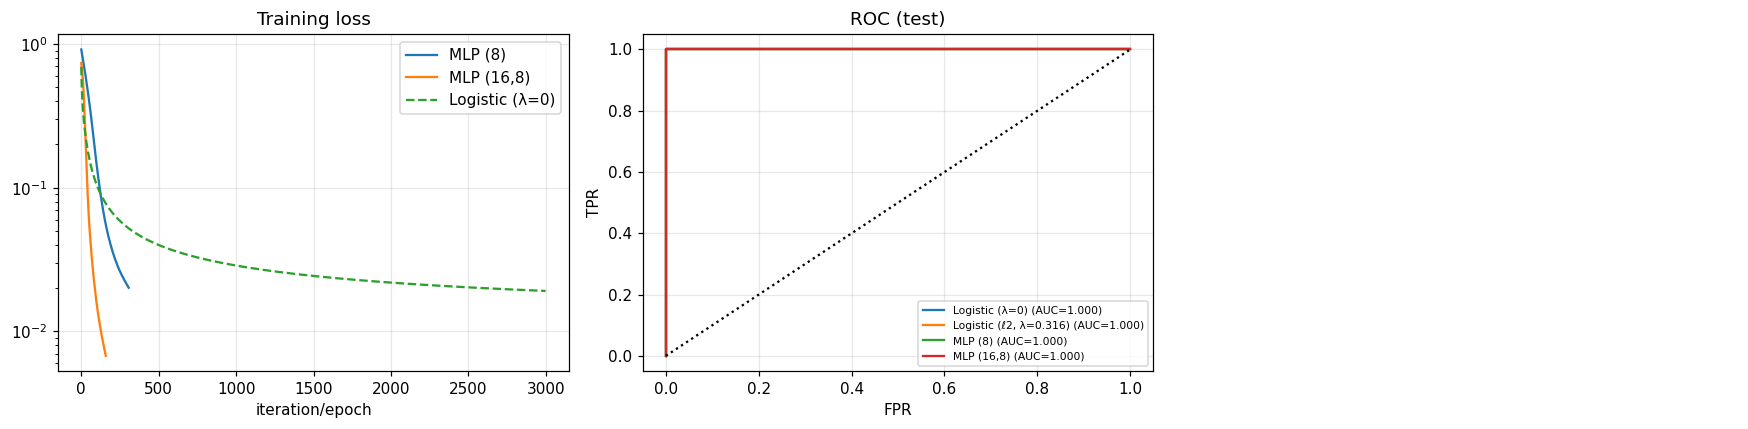

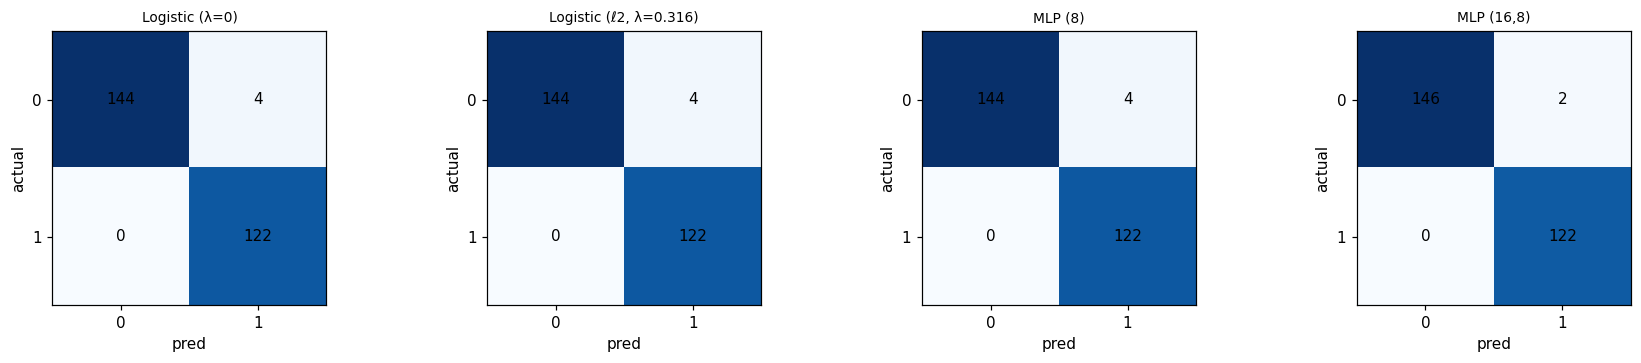

In [6]:
def n_params_mlp(m): return sum(c.size for c in m.coefs_) + sum(b.size for b in m.intercepts_)

fitted = {}
fitted["Logistic (λ=0)"] = (lr_plain, t_plain, Xc_tr_s.shape[1] + 1)
fitted[f"Logistic (ℓ2, λ={best_lam:.3g})"] = (lr_l2, t_l2, Xc_tr_s.shape[1] + 1)
for name, hl in [("MLP (8)", (8,)), ("MLP (16,8)", (16, 8))]:
    t0 = time.time(); m = MLPClassifier(hl, max_iter=1500, random_state=SEED).fit(Xc_tr_s, yc_tr); fitted[name] = (m, time.time() - t0, n_params_mlp(m))

rows = []
for name, (m, tt, npar) in fitted.items():
    p_te = m.predict_proba(Xc_te_s) if isinstance(m, LogisticGD) else m.predict_proba(Xc_te_s)[:, 1]
    yp_tr, yp_te = m.predict(Xc_tr_s), m.predict(Xc_te_s)
    rows.append([name, acc(yc_tr, yp_tr), acc(yc_te, yp_te), acc(yc_tr, yp_tr) - acc(yc_te, yp_te),
                 precision_score(yc_te, yp_te), recall_score(yc_te, yp_te), f1_score(yc_te, yp_te), roc_auc_score(yc_te, p_te), tt, npar])
    summary[name] = {"test_acc": rows[-1][2], "f1": rows[-1][6], "gap": rows[-1][3], "fit_time": tt, "params": npar}
q4 = pd.DataFrame(rows, columns=["Model", "Train acc", "Test acc", "Gap", "Precision", "Recall", "F1", "ROC-AUC", "Fit time (s)", "#Params"])
display(q4.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name in ["MLP (8)", "MLP (16,8)"]: ax[0].plot(fitted[name][0].loss_curve_, label=name)
ax[0].plot(fitted["Logistic (λ=0)"][0].hist, label="Logistic (λ=0)", ls="--"); ax[0].set_yscale("log"); ax[0].set_title("Training loss"); ax[0].set_xlabel("iteration/epoch"); ax[0].legend()
for name, (m, _, _) in fitted.items():
    p_te = m.predict_proba(Xc_te_s) if isinstance(m, LogisticGD) else m.predict_proba(Xc_te_s)[:, 1]
    fpr, tpr, _ = roc_curve(yc_te, p_te); ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_te, p_te):.3f})")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_title("ROC (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=7)
ax[2].axis("off"); ax[2].grid(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, (name, (m, _, _)) in zip(ax, fitted.items()):
    cm = confusion_matrix(yc_te, m.predict(Xc_te_s)); a.imshow(cm, cmap="Blues"); a.set_title(name, fontsize=9); a.grid(False)
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xlabel("pred"); a.set_ylabel("actual")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center")
plt.tight_layout(); plt.show()

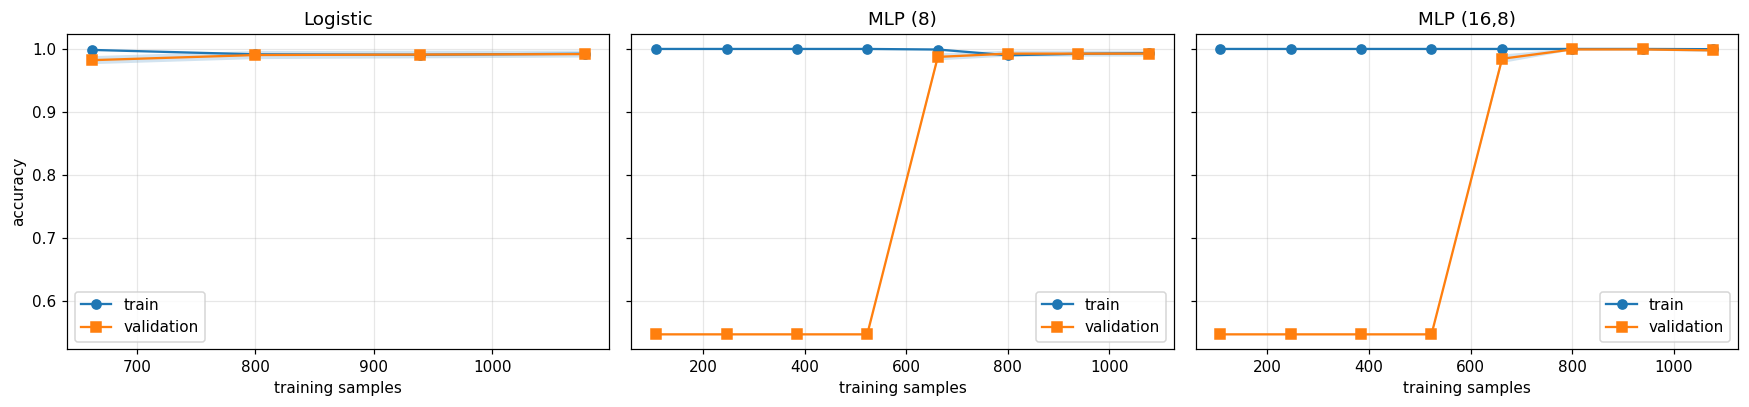

In [7]:
# Generalisation diagnostics: learning curves (5-fold CV on the full data, accuracy vs #training samples)
lc_models = {"Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
             "MLP (8)": make_pipeline(StandardScaler(), MLPClassifier((8,), max_iter=1500, random_state=SEED)),
             "MLP (16,8)": make_pipeline(StandardScaler(), MLPClassifier((16, 8), max_iter=1500, random_state=SEED))}
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a, (name, est) in zip(ax, lc_models.items()):
    sz, trs, vas = learning_curve(est, Xc, yc, train_sizes=np.linspace(.1, 1, 8), cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
    a.plot(sz, trs.mean(1), "o-", label="train"); a.plot(sz, vas.mean(1), "s-", label="validation")
    a.fill_between(sz, vas.mean(1) - vas.std(1), vas.mean(1) + vas.std(1), alpha=.2); a.set_title(name); a.set_xlabel("training samples"); a.legend()
ax[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

## Q5. Dimensionality reduction with PCA

PCA is **unsupervised**: it keeps directions of maximal *variance*, not of maximal *class separation*. We (a) inspect explained variance and loadings, (b) classify in the space of the first $k$ principal components for $k=1..d$ and compare with the original space, (c) check how well the high-variance directions align with the discriminative direction of the classifier, and (d) visualise the reduced space. PCA is fitted on the training set only (inside a pipeline during CV, to avoid leakage).

,PC1,PC2,PC3,PC4
explained var.,0.5461,0.3214,0.0898,0.0427
cumulative,0.5461,0.8675,0.9573,1.0000


,PC1,PC2,PC3,PC4
variance,0.278,0.735,0.615,-0.063
skewness,0.639,-0.063,-0.135,0.755
curtosis,-0.616,-0.129,0.495,0.599
entropy,-0.368,0.663,-0.599,0.259


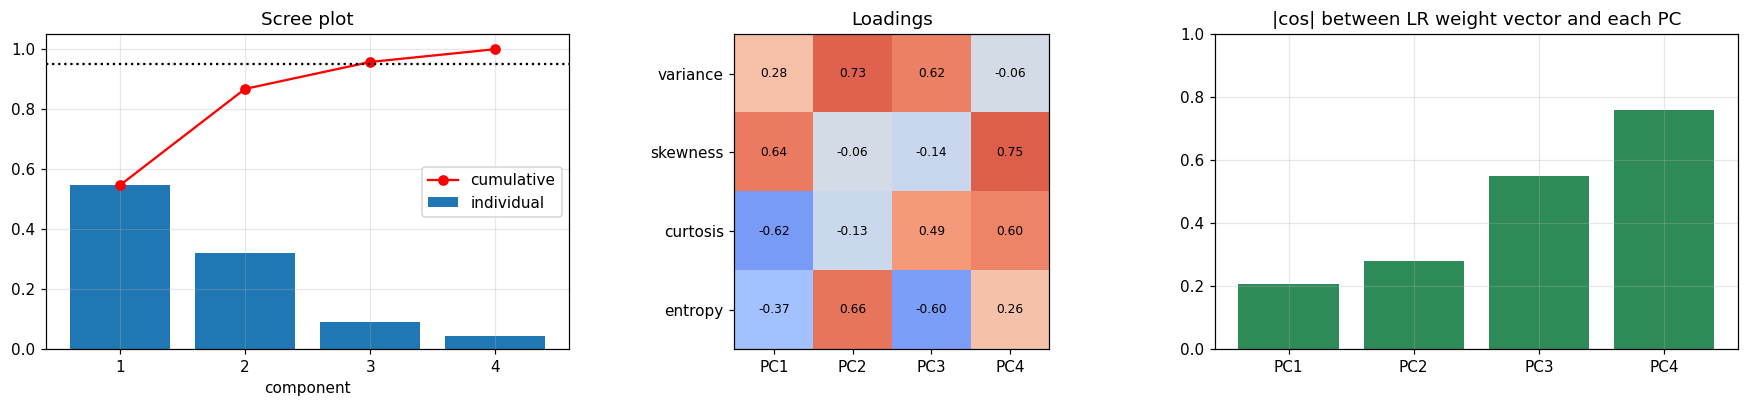

Components needed for 95% variance: 3 of 4


In [8]:
pca = PCA().fit(Xc_tr_s); evr = pca.explained_variance_ratio_; cum = np.cumsum(evr); d = len(feats)
load = pd.DataFrame(pca.components_.T, index=feats, columns=[f"PC{i+1}" for i in range(d)])
display(pd.DataFrame({"explained var.": evr, "cumulative": cum}, index=load.columns).round(4).T)
display(load.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(range(1, d + 1), evr, label="individual"); ax[0].plot(range(1, d + 1), cum, "ro-", label="cumulative"); ax[0].axhline(.95, ls=":", c="k")
ax[0].set_xticks(range(1, d + 1)); ax[0].set_title("Scree plot"); ax[0].set_xlabel("component"); ax[0].legend()
im = ax[1].imshow(load.values, cmap="coolwarm", vmin=-1, vmax=1); ax[1].grid(False); ax[1].set_xticks(range(d)); ax[1].set_xticklabels(load.columns)
ax[1].set_yticks(range(d)); ax[1].set_yticklabels(feats); ax[1].set_title("Loadings")
for (i, j), v in np.ndenumerate(load.values): ax[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
# alignment between the classifier's weight direction and each PC
w_dir = lr_plain.theta[1:, 0] / np.linalg.norm(lr_plain.theta[1:, 0])
cosines = np.abs(pca.components_ @ w_dir)
ax[2].bar(load.columns, cosines, color="seagreen"); ax[2].set_ylim(0, 1); ax[2].set_title("|cos| between LR weight vector and each PC")
plt.tight_layout(); plt.show()
print("Components needed for 95% variance:", int(np.searchsorted(cum, .95) + 1), "of", d)

,Cum. var.,LR CV acc,LR CV std,LR test acc,MLP CV acc,MLP CV std,MLP test acc
Space,,,,,,,
PCA k=1,0.5461,0.6160,0.0289,0.6111,0.6189,0.0292,0.6037
PCA k=2,0.8675,0.7676,0.0233,0.7704,0.8037,0.0247,0.7889
PCA k=3,0.9573,0.9199,0.0178,0.9148,0.9323,0.0143,0.9407
PCA k=4 (all PCs),1.0000,0.9921,0.0045,0.9852,0.9928,0.0042,0.9852
ORIGINAL features,1.0000,0.9921,0.0045,0.9852,0.9928,0.0042,0.9852


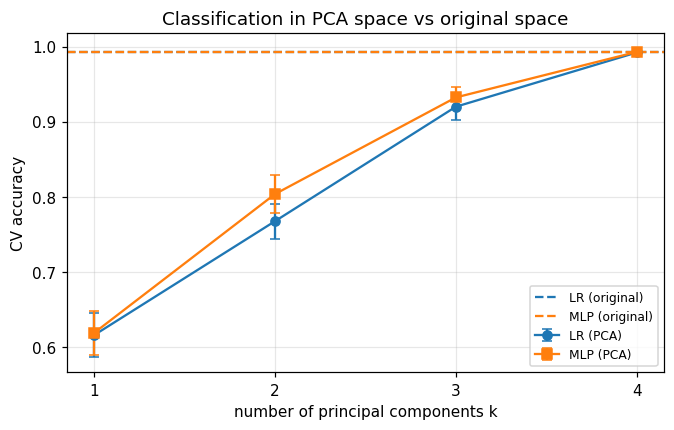

LR: best PCA k=4 -> CV acc 0.9921 vs original 0.9921  (Δ = +0.0000)
MLP: best PCA k=4 -> CV acc 0.9928 vs original 0.9928  (Δ = +0.0000)


In [9]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
def clf_factory(kind):
    return LogisticRegression(max_iter=5000) if kind == "LR" else MLPClassifier((8,), max_iter=1500, random_state=SEED)

rows = []
for k in range(1, d + 1):
    row = {"Space": f"PCA k={k}" + (" (all PCs)" if k == d else ""), "Cum. var.": cum[k - 1]}
    for kind in ["LR", "MLP"]:
        pipe = make_pipeline(StandardScaler(), PCA(n_components=k), clf_factory(kind))
        cvs = cross_val_score(pipe, Xc, yc, cv=rcv, scoring="accuracy")
        pipe.fit(Xc_tr, yc_tr); tt = pipe.score(Xc_te, yc_te)
        row[f"{kind} CV acc"] = cvs.mean(); row[f"{kind} CV std"] = cvs.std(); row[f"{kind} test acc"] = tt
    rows.append(row)
row = {"Space": "ORIGINAL features", "Cum. var.": 1.0}
for kind in ["LR", "MLP"]:
    pipe = make_pipeline(StandardScaler(), clf_factory(kind)); cvs = cross_val_score(pipe, Xc, yc, cv=rcv, scoring="accuracy")
    pipe.fit(Xc_tr, yc_tr); row[f"{kind} CV acc"] = cvs.mean(); row[f"{kind} CV std"] = cvs.std(); row[f"{kind} test acc"] = pipe.score(Xc_te, yc_te)
rows.append(row)
q5 = pd.DataFrame(rows).set_index("Space"); display(q5.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ks = np.arange(1, d + 1)
for kind, mk in [("LR", "o-"), ("MLP", "s-")]:
    ax.errorbar(ks, q5[f"{kind} CV acc"].iloc[:d], yerr=q5[f"{kind} CV std"].iloc[:d], fmt=mk, capsize=3, label=f"{kind} (PCA)")
    ax.axhline(q5.loc["ORIGINAL features", f"{kind} CV acc"], ls="--", color=ax.lines[-1].get_color(), label=f"{kind} (original)")
ax.set_xticks(ks); ax.set_xlabel("number of principal components k"); ax.set_ylabel("CV accuracy"); ax.set_title("Classification in PCA space vs original space"); ax.legend(fontsize=8); plt.show()

for kind in ["LR", "MLP"]:
    best_k = int(np.argmax(q5[f"{kind} CV acc"].iloc[:d])) + 1; orig = q5.loc["ORIGINAL features", f"{kind} CV acc"]; bk = q5[f"{kind} CV acc"].iloc[best_k - 1]
    print(f"{kind}: best PCA k={best_k} -> CV acc {bk:.4f} vs original {orig:.4f}  (Δ = {bk - orig:+.4f})")

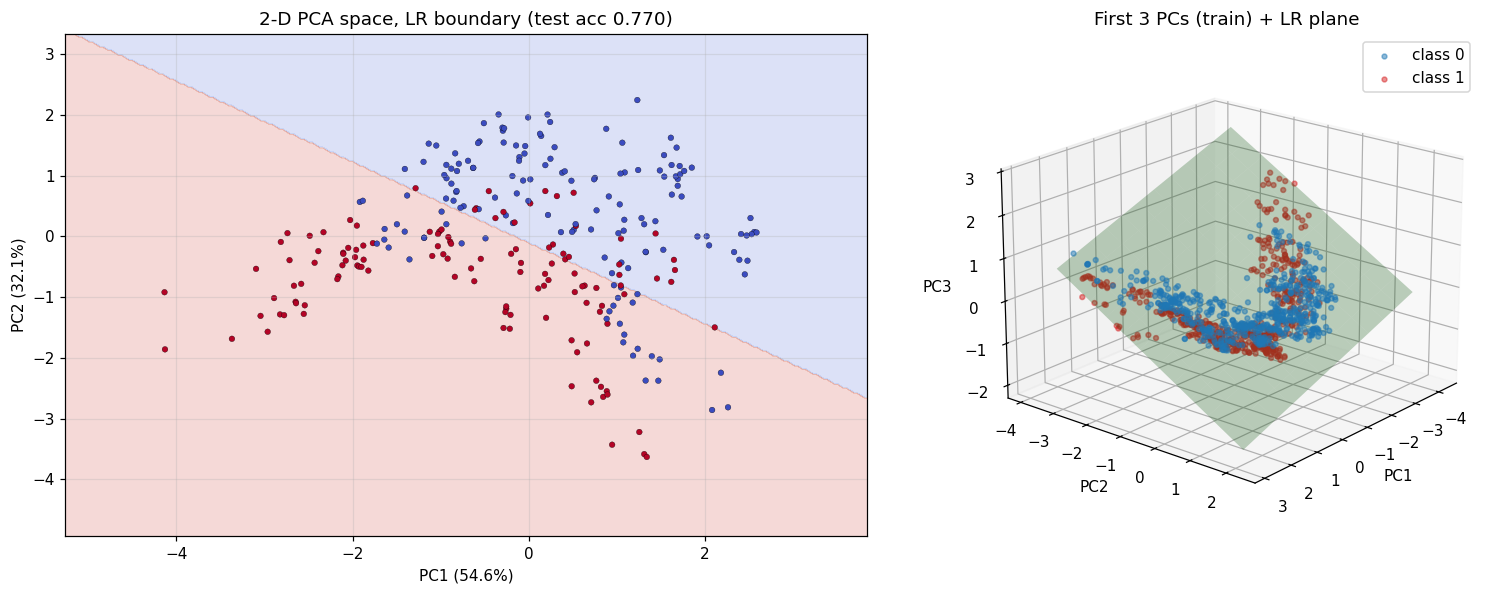

In [10]:
# Reduced-space visualisation: 2-D PCA with the LR decision boundary, and the first three PCs in 3-D with the LR plane
sc = StandardScaler().fit(Xc_tr); p2 = PCA(2).fit(sc.transform(Xc_tr)); Z_tr, Z_te = p2.transform(sc.transform(Xc_tr)), p2.transform(sc.transform(Xc_te))
lr2 = LogisticRegression(max_iter=5000).fit(Z_tr, yc_tr)
gx, gy = np.meshgrid(np.linspace(Z_tr[:, 0].min() - 1, Z_tr[:, 0].max() + 1, 300), np.linspace(Z_tr[:, 1].min() - 1, Z_tr[:, 1].max() + 1, 300))
gp = lr2.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
p3 = PCA(3).fit(sc.transform(Xc_tr)); Q_tr = p3.transform(sc.transform(Xc_tr)); lr3 = LogisticRegression(max_iter=5000).fit(Q_tr, yc_tr)

fig = plt.figure(figsize=(15, 5.5))
ax = fig.add_subplot(121); ax.contourf(gx, gy, gp, alpha=.2, cmap="coolwarm")
ax.scatter(Z_te[:, 0], Z_te[:, 1], c=yc_te, cmap="coolwarm", s=14, edgecolor="k", lw=.2)
ax.set_xlabel(f"PC1 ({evr[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr[1]:.1%})"); ax.set_title(f"2-D PCA space, LR boundary (test acc {lr2.score(Z_te, yc_te):.3f})")
ax = fig.add_subplot(122, projection="3d")
for c, col in [(0, "tab:blue"), (1, "tab:red")]: ax.scatter(*Q_tr[yc_tr == c].T, c=col, s=10, alpha=.5, label=f"class {c}")
b3, (a1, a2, a3) = lr3.intercept_[0], lr3.coef_[0]
gx3, gy3 = np.meshgrid(np.linspace(*np.percentile(Q_tr[:, 0], [1, 99]), 12), np.linspace(*np.percentile(Q_tr[:, 1], [1, 99]), 12))
gz3 = -(b3 + a1 * gx3 + a2 * gy3) / a3 if abs(a3) > 1e-8 else np.full_like(gx3, np.nan)
gz3 = np.where(np.abs(gz3) < 1.5 * np.abs(Q_tr[:, 2]).max(), gz3, np.nan); ax.plot_surface(gx3, gy3, gz3, alpha=.25, color="green")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3"); ax.set_title("First 3 PCs (train) + LR plane"); ax.legend(); ax.view_init(20, 40)
plt.tight_layout(); plt.show()

## Q6. Statistical significance testing – Friedman test and one-way ANOVA
**Design.** Six pipelines are evaluated on the *same* $N=30$ train/test partitions (5-fold stratified CV repeated 6 times); each partition is a **block**, giving 30 paired accuracy values per model. Hyper-parameters that need tuning ($\lambda$ for LR-L2) are tuned *inside* each training fold (nested), so there is no leakage.

| Test | Null hypothesis | Why used |
|---|---|---|
| **Friedman** (non-parametric, blocked on partition) | all models have the same distribution of ranks | no normality assumption; respects the paired design – the recommended test for comparing several classifiers over the same data splits (Demšar, 2006) |
| **One-way ANOVA** (parametric) | all models have the same mean accuracy | requested; assumes normality, equal variances and independence |
| Post-hoc: **Nemenyi** (after Friedman), **Tukey HSD** (after ANOVA) | pairwise equality | locate *which* models differ, controlling family-wise error |


,mean acc,std,min,max,mean F1,mean fit time (s)
LR (no reg),0.9941,0.0044,0.9852,1.0000,0.9935,0.0085
"LR (L2, CV-λ)",0.9939,0.0044,0.9778,1.0000,0.9933,0.2090
MLP (8),0.9927,0.0043,0.9815,1.0000,0.9920,0.6582
"MLP (16,8)",0.9984,0.0030,0.9889,1.0000,0.9982,0.5275
PCA(95%)+LR,0.9194,0.0176,0.8778,0.9517,0.9108,0.0077
PCA(95%)+MLP,0.9318,0.0154,0.8963,0.9628,0.9251,1.2702


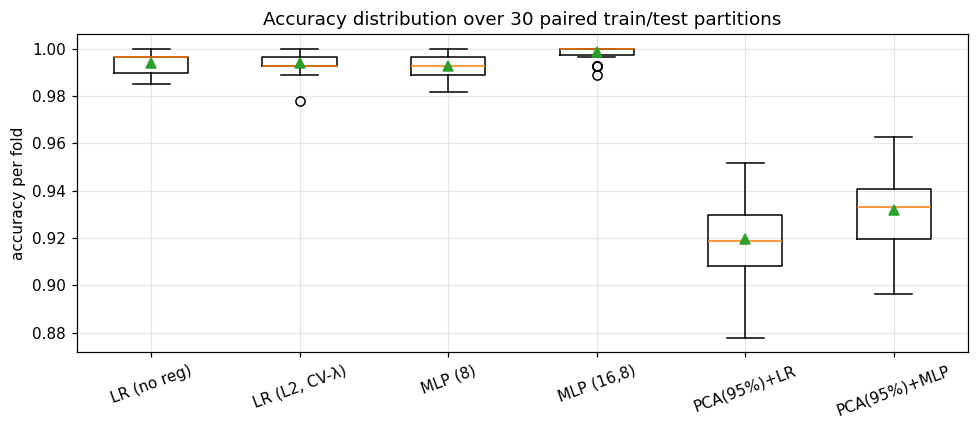

In [11]:
models = {
    "LR (no reg)":    make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=5000)),
    "LR (L2, CV-λ)":  make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 4, 15), cv=5, max_iter=5000)),
    "MLP (8)":        make_pipeline(StandardScaler(), MLPClassifier((8,), max_iter=1500, random_state=SEED)),
    "MLP (16,8)":     make_pipeline(StandardScaler(), MLPClassifier((16, 8), max_iter=1500, random_state=SEED)),
    "PCA(95%)+LR":    make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression(max_iter=5000)),
    "PCA(95%)+MLP":   make_pipeline(StandardScaler(), PCA(n_components=0.95), MLPClassifier((8,), max_iter=1500, random_state=SEED)),
}
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=SEED).split(Xc, yc))
names = list(models); k = len(names); N = len(splits)
S = np.zeros((N, k)); F1s = np.zeros((N, k)); T = np.zeros((N, k))
for j, nm in enumerate(names):
    for i, (tr, te) in enumerate(splits):
        t0 = time.time(); m = clone(models[nm]).fit(Xc[tr], yc[tr]); T[i, j] = time.time() - t0
        yp = m.predict(Xc[te]); S[i, j] = accuracy_score(yc[te], yp); F1s[i, j] = f1_score(yc[te], yp)
scores = pd.DataFrame(S, columns=names)
display(pd.DataFrame({"mean acc": S.mean(0), "std": S.std(0, ddof=1), "min": S.min(0), "max": S.max(0), "mean F1": F1s.mean(0), "mean fit time (s)": T.mean(0)}, index=names).round(4))

plt.figure(figsize=(9, 4)); plt.boxplot([S[:, j] for j in range(k)], labels=names, showmeans=True); plt.xticks(rotation=20)
plt.ylabel("accuracy per fold"); plt.title(f"Accuracy distribution over {N} paired train/test partitions"); plt.tight_layout(); plt.show()

In [12]:
# ---------------- Friedman test ----------------
ranks = np.apply_along_axis(lambda r: stats.rankdata(-r), 1, S)         # rank 1 = best in each block, ties get average ranks
avg_rank = ranks.mean(0)
try:
    chi2_f, p_f = stats.friedmanchisquare(*[S[:, j] for j in range(k)])
except Exception as e:
    chi2_f, p_f = np.nan, np.nan; print("Friedman failed:", e)
W = chi2_f / (N * (k - 1)) if np.isfinite(chi2_f) else np.nan            # Kendall's W (effect size, 0..1)
print(f"Friedman: χ²({k-1}) = {chi2_f:.3f}, p = {p_f:.4g}, Kendall's W = {W:.3f}")
print(pd.Series(avg_rank, index=names).sort_values().round(3).rename("average rank (1 = best)").to_string())

# Nemenyi post-hoc (Demšar 2006): |R_i - R_j| > CD  <=>  significant
se = np.sqrt(k * (k + 1) / (6 * N))
qdiff = np.abs(avg_rank[:, None] - avg_rank[None, :]) / se * np.sqrt(2)
P_nem_arr = np.array(stats.studentized_range.sf(qdiff, k, np.inf), dtype=float); np.fill_diagonal(P_nem_arr, 1.0)
P_nem = pd.DataFrame(P_nem_arr, index=names, columns=names)
CD = stats.studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * se
print(f"Nemenyi critical difference (α=0.05) = {CD:.3f} rank units")

# ---------------- One-way ANOVA ----------------
F_a, p_a = stats.f_oneway(*[S[:, j] for j in range(k)])
grand = S.mean(); ssb = sum(N * (S[:, j].mean() - grand) ** 2 for j in range(k)); sst = ((S - grand) ** 2).sum(); eta2 = ssb / sst
print(f"\nOne-way ANOVA: F({k-1}, {k*(N-1)}) = {F_a:.3f}, p = {p_a:.4g}, η² = {eta2:.4f}")
tuk = stats.tukey_hsd(*[S[:, j] for j in range(k)]); P_tuk = pd.DataFrame(np.array(tuk.pvalue, dtype=float), index=names, columns=names)

# assumption checks for ANOVA
sh = {nm: (stats.shapiro(S[:, j]).pvalue if np.ptp(S[:, j]) > 0 else np.nan) for j, nm in enumerate(names)}
lev = stats.levene(*[S[:, j] for j in range(k)])
print("Shapiro–Wilk p (normality) :", {a: (round(float(b), 4) if b == b else "constant") for a, b in sh.items()})
print(f"Levene p (equal variances) : {lev.pvalue:.4g}")

Friedman: χ²(5) = 134.046, p = 3.294e-27, Kendall's W = 0.894
MLP (16,8)       1.333
LR (no reg)      2.633
LR (L2, CV-λ)    2.767
MLP (8)          3.267
PCA(95%)+MLP     5.100
PCA(95%)+LR      5.900
Nemenyi critical difference (α=0.05) = 1.377 rank units

One-way ANOVA: F(5, 174) = 379.869, p = 1.306e-91, η² = 0.9161
Shapiro–Wilk p (normality) : {'LR (no reg)': 0.0046, 'LR (L2, CV-λ)': 0.0002, 'MLP (8)': 0.0372, 'MLP (16,8)': 0.0, 'PCA(95%)+LR': 0.5668, 'PCA(95%)+MLP': 0.8139}
Levene p (equal variances) : 5.948e-17


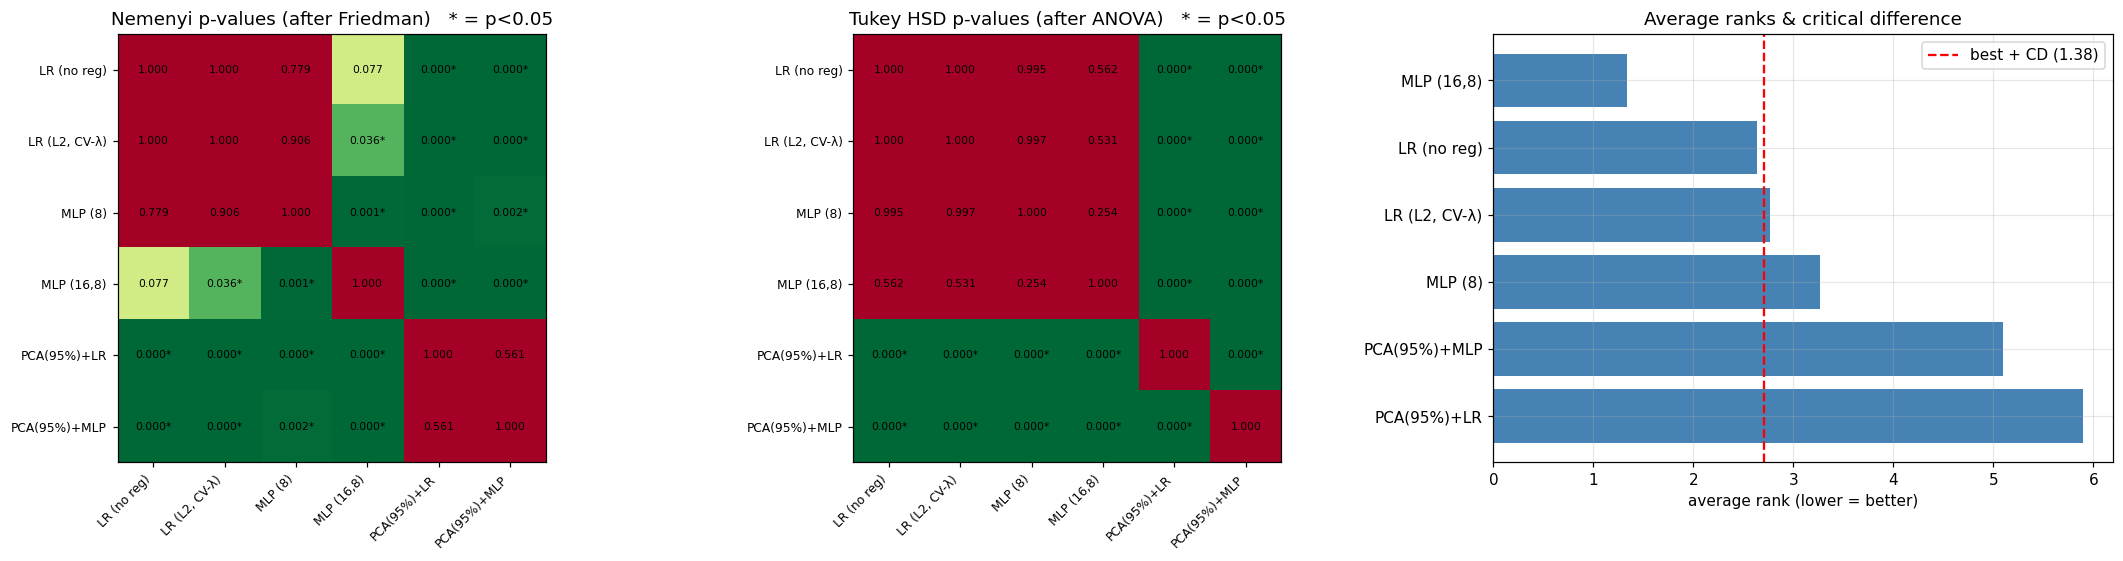

Significantly different pairs (Nemenyi): [('LR (no reg)', 'PCA(95%)+LR'), ('LR (no reg)', 'PCA(95%)+MLP'), ('LR (L2, CV-λ)', 'MLP (16,8)'), ('LR (L2, CV-λ)', 'PCA(95%)+LR'), ('LR (L2, CV-λ)', 'PCA(95%)+MLP'), ('MLP (8)', 'MLP (16,8)'), ('MLP (8)', 'PCA(95%)+LR'), ('MLP (8)', 'PCA(95%)+MLP'), ('MLP (16,8)', 'PCA(95%)+LR'), ('MLP (16,8)', 'PCA(95%)+MLP')]
Significantly different pairs (Tukey)  : [('LR (no reg)', 'PCA(95%)+LR'), ('LR (no reg)', 'PCA(95%)+MLP'), ('LR (L2, CV-λ)', 'PCA(95%)+LR'), ('LR (L2, CV-λ)', 'PCA(95%)+MLP'), ('MLP (8)', 'PCA(95%)+LR'), ('MLP (8)', 'PCA(95%)+MLP'), ('MLP (16,8)', 'PCA(95%)+LR'), ('MLP (16,8)', 'PCA(95%)+MLP'), ('PCA(95%)+LR', 'PCA(95%)+MLP')]
Best average rank: MLP (16,8) | models statistically indistinguishable from it (within CD): ['LR (no reg)', 'MLP (16,8)']


In [13]:
def heat(ax, Pm, title):
    im = ax.imshow(Pm.values.astype(float), cmap="RdYlGn_r", vmin=0, vmax=.2); ax.grid(False)
    ax.set_xticks(range(k)); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(k)); ax.set_yticklabels(names, fontsize=8)
    for i in range(k):
        for j in range(k): ax.text(j, i, f"{Pm.values[i, j]:.3f}" + ("*" if (i != j and Pm.values[i, j] < .05) else ""), ha="center", va="center", fontsize=7)
    ax.set_title(title)

fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
heat(ax[0], P_nem, "Nemenyi p-values (after Friedman)   * = p<0.05"); heat(ax[1], P_tuk, "Tukey HSD p-values (after ANOVA)   * = p<0.05")
order = np.argsort(avg_rank); ax[2].barh(np.array(names)[order][::-1], avg_rank[order][::-1], color="steelblue"); ax[2].set_xlabel("average rank (lower = better)")
ax[2].axvline(avg_rank.min() + CD, color="r", ls="--", label=f"best + CD ({CD:.2f})"); ax[2].legend(); ax[2].set_title("Average ranks & critical difference")
plt.tight_layout(); plt.show()

sig_nem = [(names[i], names[j]) for i in range(k) for j in range(i + 1, k) if P_nem.values[i, j] < .05]
sig_tuk = [(names[i], names[j]) for i in range(k) for j in range(i + 1, k) if P_tuk.values[i, j] < .05]
print("Significantly different pairs (Nemenyi):", sig_nem if sig_nem else "none")
print("Significantly different pairs (Tukey)  :", sig_tuk if sig_tuk else "none")
best_rank_model = names[int(np.argmin(avg_rank))]
statistically_tied = [names[j] for j in range(k) if abs(avg_rank[j] - avg_rank.min()) <= CD]
print("Best average rank:", best_rank_model, "| models statistically indistinguishable from it (within CD):", statistically_tied)
summary["_stats"] = dict(friedman_p=p_f, anova_p=p_a, best=best_rank_model, tied=statistically_tied, means=dict(zip(names, S.mean(0))), times=dict(zip(names, T.mean(0))))

## Q7. Supplement – robustness to outliers and interpretability


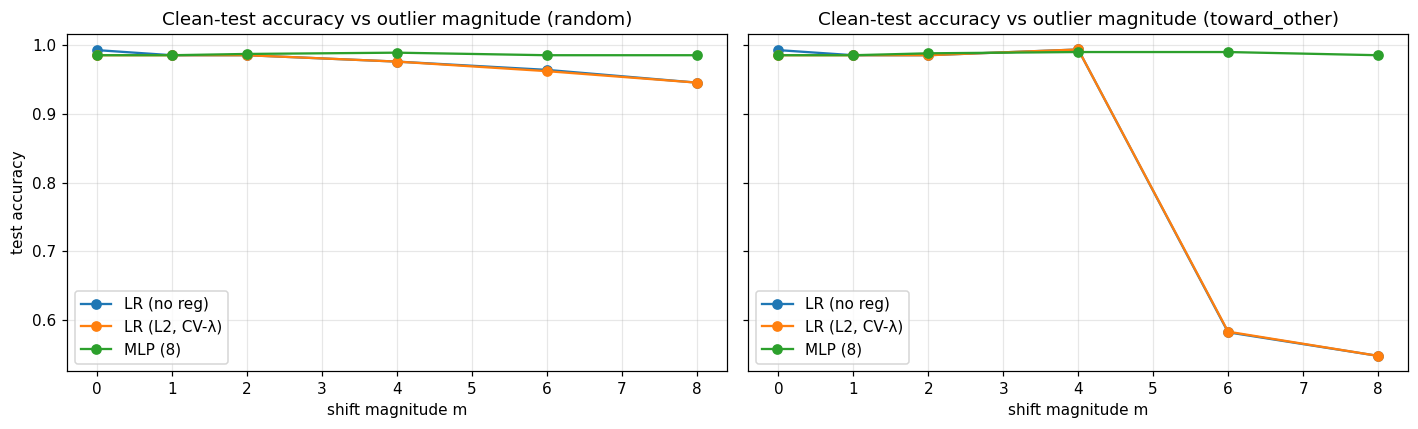

,m=0,m=1,m=2,m=4,m=6,m=8
LR (no reg) | random,0.9926,0.9852,0.9852,0.9759,0.9639,0.9454
"LR (L2, CV-λ) | random",0.9852,0.9852,0.9852,0.9759,0.9620,0.9454
MLP (8) | random,0.9852,0.9852,0.9870,0.9889,0.9852,0.9852
LR (no reg) | toward_other,0.9926,0.9852,0.9852,0.9935,0.5824,0.5481
"LR (L2, CV-λ) | toward_other",0.9852,0.9852,0.9852,0.9935,0.5833,0.5481
MLP (8) | toward_other,0.9852,0.9852,0.9880,0.9898,0.9898,0.9852


In [14]:
def inject_outliers(X, y, frac=0.05, magnitude=4.0, mode="random", seed=0):
    rng = np.random.default_rng(seed); Xo = X.copy(); n = len(X)
    idx = rng.choice(n, int(round(frac * n)), replace=False); sigma = X.std(0)
    if mode == "random":
        Xo[idx] += magnitude * sigma * rng.choice([-1, 1], size=(len(idx), X.shape[1]))
    else:
        mus = {c: X[y == c].mean(0) for c in np.unique(y)}
        for i in idx: Xo[i] += magnitude * (mus[1 - y[i]] - mus[y[i]])
    return Xo

rob_models = {"LR (no reg)": models["LR (no reg)"], "LR (L2, CV-λ)": models["LR (L2, CV-λ)"], "MLP (8)": models["MLP (8)"]}
mags = [0, 1, 2, 4, 6, 8]; n_rep = 4
rob = {mode: {nm: np.zeros(len(mags)) for nm in rob_models} for mode in ["random", "toward_other"]}
for mode in rob:
    for a_, mg in enumerate(mags):
        for nm, est in rob_models.items():
            vals = []
            for r in range(n_rep):
                Xo = inject_outliers(Xc_tr, yc_tr, 0.05, mg, mode, seed=r)
                vals.append(clone(est).fit(Xo, yc_tr).score(Xc_te, yc_te))
            rob[mode][nm][a_] = np.mean(vals)

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, mode in zip(ax, rob):
    for nm, v in rob[mode].items(): a.plot(mags, v, "o-", label=nm)
    a.set_title(f"Clean-test accuracy vs outlier magnitude ({mode})"); a.set_xlabel("shift magnitude m"); a.legend()
ax[0].set_ylabel("test accuracy"); plt.tight_layout(); plt.show()
rob_tbl = pd.DataFrame({f"{nm} | {mode}": rob[mode][nm] for mode in rob for nm in rob_models}, index=[f"m={m}" for m in mags]).T; display(rob_tbl.round(4))
for nm in rob_models: summary.setdefault(nm if nm in summary else nm, {})["outlier_drop_toward_m4"] = rob["toward_other"][nm][0] - rob["toward_other"][nm][mags.index(4)]

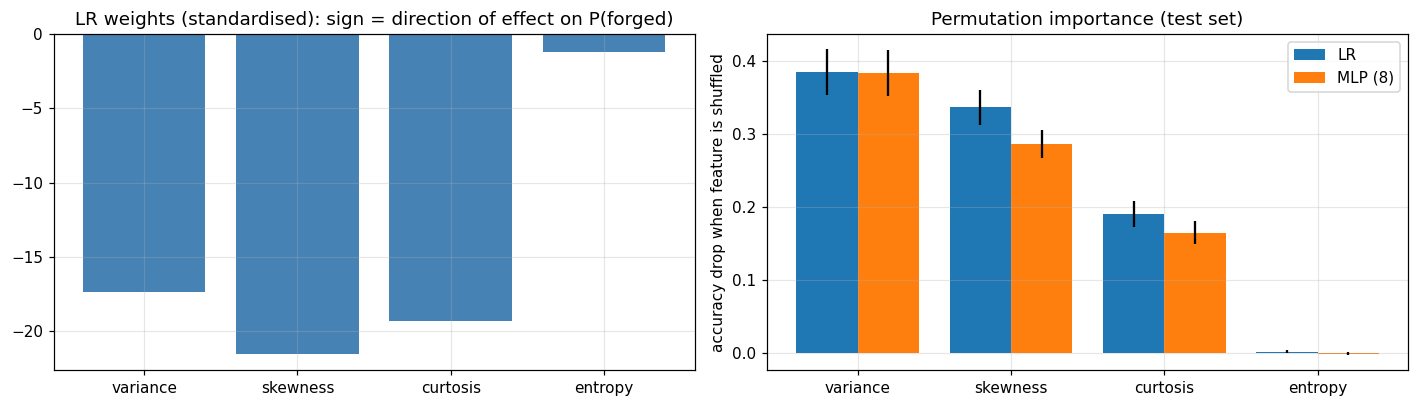

In [15]:
# Interpretability: LR weights (direct, signed) vs permutation importance (model-agnostic, works for both)
lr_pipe = clone(models["LR (no reg)"]).fit(Xc_tr, yc_tr); mlp_pipe = clone(models["MLP (8)"]).fit(Xc_tr, yc_tr)
pi_lr = permutation_importance(lr_pipe, Xc_te, yc_te, n_repeats=30, random_state=SEED, scoring="accuracy")
pi_mlp = permutation_importance(mlp_pipe, Xc_te, yc_te, n_repeats=30, random_state=SEED, scoring="accuracy")
coef = lr_pipe[-1].coef_[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(feats, coef, color=np.where(coef > 0, "indianred", "steelblue")); ax[0].set_title("LR weights (standardised): sign = direction of effect on P(forged)")
x = np.arange(len(feats)); ax[1].bar(x - .2, pi_lr.importances_mean, .4, yerr=pi_lr.importances_std, label="LR"); ax[1].bar(x + .2, pi_mlp.importances_mean, .4, yerr=pi_mlp.importances_std, label="MLP (8)")
ax[1].set_xticks(x); ax[1].set_xticklabels(feats); ax[1].set_ylabel("accuracy drop when feature is shuffled"); ax[1].set_title("Permutation importance (test set)"); ax[1].legend()
plt.tight_layout(); plt.show()

## Q8. Final verdict – linear model or neural network?
The cell below assembles the evidence from Q4, Q6 and Q7 and prints a data-driven recommendation.

In [16]:
rows = []
for nm in ["Logistic (λ=0)", f"Logistic (ℓ2, λ={best_lam:.3g})", "MLP (8)", "MLP (16,8)"]:
    s = summary[nm]; rows.append([nm, s["test_acc"], s["f1"], s["gap"], s["fit_time"], s["params"]])
final = pd.DataFrame(rows, columns=["Model", "Test acc", "Test F1", "Train−test gap", "Fit time (s)", "#Params"])
final["Mean CV acc (Q6)"] = [summary["_stats"]["means"].get(n, np.nan) for n in ["LR (no reg)", "LR (L2, CV-λ)", "MLP (8)", "MLP (16,8)"]]
final["Acc drop, outliers m=4 (Q7)"] = [summary["LR (no reg)"].get("outlier_drop_toward_m4", np.nan), summary["LR (L2, CV-λ)"].get("outlier_drop_toward_m4", np.nan), summary["MLP (8)"].get("outlier_drop_toward_m4", np.nan), np.nan]
final["Interpretability"] = ["High (weights, one hyperplane)", "High (shrunk weights)", "Low (black box)", "Low (black box)"]
display(final.round(4))

st = summary["_stats"]
print(f"Friedman p = {st['friedman_p']:.4g} | ANOVA p = {st['anova_p']:.4g}")
lin_names = {"LR (no reg)", "LR (L2, CV-λ)"}
if not np.isfinite(st["friedman_p"]) or st["friedman_p"] >= 0.05:
    print("RECOMMENDATION: No significant difference among the models (Friedman p ≥ 0.05) -> choose the LINEAR model (logistic regression, "
          "ℓ2-regularised): equal accuracy, far simpler, interpretable, cheaper and more stable.")
elif st["best"] in lin_names or any(t in lin_names for t in st["tied"]):
    print(f"RECOMMENDATION: Significant differences exist, but a linear model is the best or statistically tied with the best ({st['tied']}) "
          "-> prefer the LINEAR model by parsimony: no evidence the neural network adds value.")
else:
    gain = max(st["means"].values()) - max(st["means"][n] for n in lin_names)
    print(f"RECOMMENDATION: The best model ({st['best']}) is significantly better than the linear models, by {gain*100:.2f} percentage points "
          "of accuracy. Adopt it only if this gain outweighs the loss of interpretability, higher variance and weaker outlier robustness; otherwise keep the linear model.")

,Model,Test acc,Test F1,Train−test gap,Fit time (s),#Params,Mean CV acc (Q6),"Acc drop, outliers m=4 (Q7)",Interpretability
0,Logistic (λ=0),0.9852,0.9839,0.0092,0.5956,5,0.9941,-0.0009,"High (weights, one hyperplane)"
1,"Logistic (ℓ2, λ=0.316)",0.9852,0.9839,0.0092,0.7454,5,0.9939,-0.0083,High (shrunk weights)
2,MLP (8),0.9852,0.9839,0.0102,0.9446,49,0.9927,-0.0046,Low (black box)
3,"MLP (16,8)",0.9926,0.9919,0.0065,0.7640,225,0.9984,NaN,Low (black box)


Friedman p = 3.294e-27 | ANOVA p = 1.306e-91
RECOMMENDATION: Significant differences exist, but a linear model is the best or statistically tied with the best (['LR (no reg)', 'MLP (16,8)']) -> prefer the LINEAR model by parsimony: no evidence the neural network adds value.
